# *Projeto de teste para o ambiente do Deep-Tomography 2.0*

# Loading basic libraries

In [1]:


import os
from datetime import datetime
import time
import random
import sys
import struct
from glob import glob
import pickle

from scipy import ndimage
from scipy import interpolate
#from skimage import io as skio
from scipy import fftpack

import numpy as np
import torch
import torch.nn as nn
import seaborn as sns
# import cv2


#get_ipython().magic('matplotlib inline')
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import matplotlib.colors as mcolors0

from PIL import Image
import segyio

import mlflow
from mlflow import MlflowClient

import sklearn
from sklearn.model_selection import GridSearchCV


import sys
print("Python version")
print (sys.version)
print("Version info.")
print (sys.version_info)
print("")
print("Matplotlib version")
print('{}'.format(matplotlib.__version__))

#!pip install matplotlib --upgrade
print("")




Python version
3.11.9 (tags/v3.11.9:de54cf5, May  7 2024, 16:25:05) [GCC 11.4.0]
Version info.
sys.version_info(major=3, minor=11, micro=9, releaselevel='final', serial=0)

Matplotlib version
3.8.3



# Loading Auxiliary Classes

In [ ]:

import importlib

local_logging = importlib.import_module("src.utl.logging")
importlib.reload(local_logging)

local_classes = importlib.import_module("src.utl.classes")
importlib.reload(local_classes)

local_serialization = importlib.import_module("src.utl.serialization")
importlib.reload(local_serialization)

local_data = importlib.import_module("src.data.data")
importlib.reload(local_data)

local_data_viewer = importlib.import_module("src.visualization.data_viewer")
importlib.reload(local_data_viewer)

local_data_builder = importlib.import_module("src.data.data_builder")
importlib.reload(local_data_builder)

local_pipeline = importlib.import_module("src.preprocessing.pipeline")
importlib.reload(local_pipeline)

local_exp_track_api = importlib.import_module("src.experiment_tracking.exptrack_interface")
importlib.reload(local_exp_track_api)

local_mlflow = importlib.import_module("src.experiment_tracking.mlflow")
importlib.reload(local_mlflow)

local_mlflow_utils = importlib.import_module("src.experiment_tracking.mlflow_utils")
importlib.reload(local_mlflow_utils)

local_mlmodels = importlib.import_module("src.processing.ml_models")
importlib.reload(local_mlmodels)

local_mlmodels_builder = importlib.import_module("src.processing.ml_models_builder")
importlib.reload(local_mlmodels_builder)

local_vit_seg_configs = importlib.import_module("src.transunet.vit_seg_configs")
importlib.reload(local_vit_seg_configs)

local_vit_seg_modeling = importlib.import_module("src.transunet.vit_seg_modeling")
importlib.reload(local_vit_seg_modeling)


#local_pipeline = importlib.import_module("src.preprocessing.local_pipeline")
#local_pipeline = importlib.import_module("src.preprocessing.local_pipeline")
#importlib.reload(local_pipeline)

from src.experiment_tracking.mlflow_utils import MLFlowUtils
from src.experiment_tracking.mlflow import MLFlow

from src.processing.ml_models_builder import SkorchTransUNetModelBuilder, ScoredSkorchModel
from src.processing.ml_models import TransUNet

from src.utl.logging import Log as log

from src.utl.classes import ProjectDirs, BuildDirectories
from src.utl.classes import Utils as utl
from src.utl.classes import Graph as graph

from src.data.data_builder import BuildDeepTomographyDataAndModels
#from src.local_data import Data, DeepTomographyModels
from src.visualization.data_viewer import DataAndModelsViewer as viewer

from src.preprocessing.pipeline import Preprocessing

#from src.preprocessing.local_pipeline import PreprocessingPipe
#from src.processing.train_data import TrainDataInfo, TrainData, Jobs, ProductionOutlierClassification







# Defining paths for input \ output files

In [ ]:

#old data
#basedir = "/gemini/tg/ntbs/doutorado/4semestre/inf2475/trabalho.final/deeptomograph_data/data/"
#new data
basedir = "/gemini/tg/ntbs/doutorado/4semestre/inf2475/trabalho.final/deeptomograph_data/data_new_and_bigger/"
dirs = BuildDirectories(basedir=basedir).build()
print(f"Project info: {dirs}")



# Reading training and test data and velocity models

## Holdout
The complete separation of train and test dataset is made here.

In [ ]:


SAVE = False
max_samples=-1

if max_samples == -1:
    SAVE = True

data_and_models_builder = BuildDeepTomographyDataAndModels(dirs=dirs, max_samples=max_samples, verbose=True)
train_data, test_data, train_models, test_models = data_and_models_builder.build()
is_newer_data = data_and_models_builder.is_newer_data()
log.info(f"Is newer data? {is_newer_data}")



# Preprocessing

**NOTES:**
The preprocessing is inplace.

The last step is a outplace conversion to pytorch tensor.

In [ ]:


preprocess_pipe = Preprocessing(verbose=True)
train_data, train_models = preprocess_pipe.fit_transform(data=train_data, models=train_models)
test_data, test_models = preprocess_pipe.transform(data=test_data, models=test_models)



# Understanding the data

## Selecting samples to view

In [ ]:

NSAMPLES = 1
train_samples = list()
test_samples = list()
for i in range(NSAMPLES):
    train_samples.append(random.randint(0,train_data.get_nmb_of_elems()-1))
    test_samples.append(random.randint(0,test_data.get_nmb_of_elems()-1))

log.info(f"TRAIN SAMPLES = {train_samples}")
log.info(f"TEST SAMPLES = {test_samples}")


## Train models view

In [ ]:
if train_models is not None: 
    viewer.model_view(models=train_models, nsamples=NSAMPLES, samples=train_samples, colorbar=True)


## Test models view

In [ ]:
if test_models is not None: 
    viewer.model_view(models=test_models, nsamples=NSAMPLES, samples=test_samples)


## Train supervised-data view
### X view

In [ ]:



viewer.x_view(data=train_data.get_highres_data().get_X(), nsamples=2, samples=train_samples, colorbar=False, title="HIGH RES")
viewer.x_view(data=train_data.get_mediumres_data().get_X(), nsamples=2, samples=train_samples, colorbar=False, title="MEDIUM RES")
viewer.x_view(data=train_data.get_lowres_data().get_X(), nsamples=2, samples=train_samples, colorbar=False, title="LOW RES")




### XY view

In [ ]:


viewer.xy_view(data=train_data.get_highres_data(), nsamples=2, samples=train_samples, colorbar=True, title="HIGH RES")
viewer.xy_view(data=train_data.get_mediumres_data(), nsamples=2, samples=train_samples, colorbar=True, title="MEDIUM RES")
viewer.xy_view(data=train_data.get_lowres_data(), nsamples=2, samples=train_samples, colorbar=True, title="LOW RES")



## Test supervised-data view
### X view

In [ ]:


viewer.x_view(data=test_data.get_highres_data().get_X(), nsamples=2, samples=test_samples, colorbar=False, title="HIGH RES")
viewer.x_view(data=test_data.get_mediumres_data().get_X(), nsamples=2, samples=test_samples, colorbar=False, title="MEDIUM RES")
viewer.x_view(data=test_data.get_lowres_data().get_X(), nsamples=2, samples=test_samples, colorbar=False, title="LOW RES")



### XY view

In [ ]:


viewer.xy_view(data=test_data.get_highres_data(), nsamples=2, samples=test_samples, colorbar=True, title="HIGH RES")
viewer.xy_view(data=test_data.get_mediumres_data(), nsamples=2, samples=test_samples, colorbar=True, title="MEDIUM RES")
viewer.xy_view(data=test_data.get_lowres_data(), nsamples=2, samples=test_samples, colorbar=True, title="LOW RES")



## Training view (flow)

In [ ]:

if train_models is not None:
    viewer.flow_view(data=train_data, models=train_models, nsamples=2, samples=train_samples, colorbar=True)


## Test view (flow)

In [ ]:

if test_models is not None:
    viewer.flow_view(data=test_data, models=test_models, nsamples=2, samples=test_samples, colorbar=True)


# Creating machine learning model

**NOTE**: Using skorch.



## CUDA check

In [ ]:
import torch 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.cuda.empty_cache()


## Building skorch model

**NOTE**: In this work we are working with sklearn framework and pytorch cnn models. So, we use skorch to adapt pytorch models to attend sklearn model's API.

In [ ]:
from torch.optim import SGD, Adam #, Adagrad, Adamax, NAdam, Adadelta, RMSprop

import mlflow
from mlflow import MlflowClient
from skorch.callbacks import MlflowLogger

#mlflow.pytorch.autolog()


N_CHANNELS = train_data.get_highres_data().get_X().shape[1]
log.info(f"N_CHANNELS = {N_CHANNELS}")

skmodel=SkorchTransUNetModelBuilder(verbose=True).build(
              max_epochs=130, device=device,
              batch_size=16,
              #criterion=nn.SSIM(),
              criterion=nn.MSELoss(),
              optimizer=torch.optim.Adam,
              lr=0.0001,
              callbacks=[MlflowLogger(create_artifact=False)],
              in_channels=N_CHANNELS, out_channels=1, n_filters_init=16,
              conv_kernel_size=(13,13), pool_kernel_size=(2,2), pool_stride=(2,2),
              batch_normalization=True, dropout=0.2,
              #img_size=(672,800),
              attention_img_size=(21,25), #21x25=525 == sequence length quando patches.size=(1,1)
              attention_in_channels=512,  # n_channels of the last encoding feature map
              attention_hidden_size=512, # D, embedding size 
              attention_num_heads=16,
              attention_num_layers=12,
              attention_mlp_dim=4096,
              vis=False,
            )



## Model summarization

In [ ]:


shape_tmp = test_data.get_highres_data().get_X().shape
NZ_CUT, NX_CUT = utl.find_size(shape_tmp[2], shape_tmp[3])

log.info(f"ORIGINAL SHAPE: {shape_tmp}")
log.info(f"NZ_CUT, NX_CUT = {NZ_CUT, NX_CUT}")
del shape_tmp

#print(skmodel.initialize())
skmodel.initialize()
print(type(skmodel.module_))
print(skmodel.module_.summary(input_size=(1, N_CHANNELS, NZ_CUT, NX_CUT)))




#outra forma de fazer o summary
#from torchinfo import summary
#model_aux = skmodel.module_
#print(type(model_aux))
#summary(model_aux, input_size=(10, 1, NZ_CUT, NX_CUT))





# High-resolution datasets

## Cropping train and test datasets

**NOTE**: We are running just the high-resolution cnn and datasets.

In [ ]:


def transform_shape_input(X, Y, NZ_CUT, NX_CUT):
    log.info(f"AVAILABLE DEVICE = {device}")
    
    # X
    x = X[:,:,:NZ_CUT,:NX_CUT]
    log.info(f"x.shape = {x.shape}")
    
    
    # Y
    y = Y[:,:NZ_CUT,:NX_CUT]
    log.info(f"y.shape = {y.shape}    --- original shape")
    y_shape = y.shape
    y_new_shape = (y_shape[0], 1, y_shape[1], y_shape[2])
    y = y.reshape(y_new_shape)
    log.info(f"y.shape = {y.shape}    --- after reshaping")
    
    
    log.info(f"x,y current devices = {x.device}, {y.device}")
    #x = x.to(device)
    #y = y.to(device)
    #log.info(f"x,y after to(device) = {x.device}, {y.device}")
    return x, y


x_tmp = train_data.get_highres_data().get_X()
y_tmp = train_data.get_highres_data().get_Y()
x_train, y_train = transform_shape_input(x_tmp, y_tmp, NZ_CUT, NX_CUT)

x_tmp = test_data.get_highres_data().get_X()
y_tmp = test_data.get_highres_data().get_Y()
x_test, y_test = transform_shape_input(x_tmp, y_tmp, NZ_CUT, NX_CUT)




In [ ]:


def print_auto_logged_info(r):
    tags = {k: v for k, v in r.data.tags.items() if not k.startswith("mlflow.")}
    artifacts = [f.path for f in MlflowClient().list_artifacts(r.info.run_id, "model")]
    print(f"run_id: {r.info.run_id}")
    print(f"artifacts: {artifacts}")
    print(f"params: {r.data.params}")
    print(f"metrics: {r.data.metrics}")
    print(f"tags: {tags}")



# Training 

## Defining grid search parameters

In [ ]:

from src.transunet.vit_seg_configs import get_attention_regression_config


# <<< NOTE >>> For this moment in_channels and hidden_layer must be the same
# <<< NOTE 2 >>> The parameter hidden_layer below is not been used. The one which is is the module__attention_in_channels.
att_conf_l2 =  get_attention_regression_config(num_layers=2,  in_channels=512, hidden_size=512, num_heads=16, mlp_dim=4096 )
att_conf_l8 =  get_attention_regression_config(num_layers=8,  in_channels=512, hidden_size=512, num_heads=16, mlp_dim=4096 )
att_conf_l12 = get_attention_regression_config(num_layers=12, in_channels=512, hidden_size=512, num_heads=16, mlp_dim=4096 )
att_conf_l24 = get_attention_regression_config(num_layers=24, in_channels=512, hidden_size=512, num_heads=16, mlp_dim=4096 )

# define the grid search parameters
param_grid = {
    'max_epochs': [130], # 300],]
    'batch_size': [ 16 ],
    'device': ['cuda'],
    #'lr': [0.0001, 0.001, 0.01, 0.1, 0.2, 0.3],
    'lr': [0.0001],
    #'optimizer__momentum': [0.0, 0.2, 0.4, 0.6, 0.8, 0.9],
    #'optimizer__momentum': [0.0], #, 0.2, 0.4, 0.6, 0.8, 0.9],
    'optimizer': [torch.optim.Adam], #, SGD], #, RMSprop, Adagrad, Adadelta, Adam, Adamax, NAdam],
    'criterion': [nn.MSELoss], #, nn.SSIM()],
    'verbose' : [ True ],
    #'callbacks': [None],
    'module__in_channels' : [N_CHANNELS],
    'module__out_channels' : [1],
    'module__n_filters_init' : [16],
    'module__conv_kernel_size' : [(13,13)],# (5,5)],# (9,9), (13,13)],
    'module__pool_kernel_size' : [(2,2)],
    'module__pool_stride' : [(2,2)],
    'module__batch_normalization' : [True],
    'module__dropout' : [0.2],
    'module__attention_img_size' : [(21,25)],
    #'module__attention_config' : [att_conf_l2, att_conf_l8, att_conf_l12, att_conf_l24],
    'module__attention_config' : [att_conf_l12],
    'module__attention_in_channels' : [512],
    'module__vis' : [False],
    'module__verbose' : [ True ],
    }




## Running GridSearchCV 

### Experiment tracking
Using MLFlow as experiment tracking

In [ ]:




from sklearn.model_selection import ParameterGrid

#mlflow_uri="http://gr14sm02.ep.petrobras.com.br:31947/"
mlflow_uri="http://gr14sm02.ep.petrobras.com.br:31947/"
mlflow_experiment="deep_tomography_2.0"

mlflow_ = MLFlow(uri=mlflow_uri, experiment_name=mlflow_experiment, verbose=True)
mlflow_.info()
mlflow_.init()


#mlflow.sklearn.autolog()
assert x_train.shape[0] == y_train.shape[0], f"x_train and y_train must have the same number of samples."
train_idxs, val_idxs = utl.two_split(y_train.shape[0], test_perc=0.2, fixed_seed=True, verbose=True)
split_iterator = list()
split_iterator.append((train_idxs, val_idxs))

#cv=5 # para valer
#cv_str = str(cv)
cv=split_iterator # para teste
cv_str = str(1)


######
# NOTE: The code above is a workaround made because grid_result.best_estimator_ 
#       was wrong when n_searchs==1. It's necessary to change the selecton of best_estimator 
#       in the cells below.
######
#    n_searchs = len(ParameterGrid(param_grid))
#    if n_searchs == 1:
#        refit = False
#        skmodel.warm_start = True
#    else:
#        refit = True
#        skmodel.warm_start = False
#
#log.info(f"refit = {refit}")
#log.info(f"warm_start = {skmodel.warm_start}")

refit = True
grid = GridSearchCV(estimator=skmodel, error_score='raise', return_train_score=True, param_grid=param_grid, n_jobs=None, cv=cv, refit=refit, verbose=True)

# train a model
run_name = f"TFINAL__TRANSUNET_{max_samples}-samples__{cv_str}-cv__{utl.get_timestamp()}"
with mlflow.start_run(run_name=run_name) as run:
    log.info(f"Initiating running. run_id =  {run.info.run_id} -- run_name = {run.info.run_name}")
    grid_result = grid.fit(x_train, y_train)
    MLFlowUtils.log_results(grid, mlflow_uri, mlflow_experiment, model_name=None, run_name=run.info.run_name)#, tags={}, log_only_best=False)
    #skmodel.fit(y_train,y_train)
#    #print_auto_logged_info(mlflow.get_run(run_id=run.info.run_id))
#


## Summarizing training

In [ ]:



log.info("Summarize results")
# Access the best hyperparameters found by GridSearchCV
best_grid_model = grid_result.best_estimator_
best_params = grid_result.best_params_
best_score = -grid_result.best_score_
best_index = grid_result.best_index_
log.info(f"best_score = {best_score}")
log.info(f"best_index = {best_index}")
log.info(f"best_params = {best_params}")

means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    log.info("%f (%f) with: %r" % (-mean, -stdev, param))


# Evaluating

## Metric
Using the actual training loss to measure how good the model is.

*Smaller is better*.

## Retraining with the best parameteres


In [ ]:
#best_skmodel = best_grid_model   # teste

In [ ]:

aux_temp = best_params.copy()
#aux_temp['module__n_filters_init'] = 32
aux_temp['batch_size'] = 16


# Training the model with the best parameters
best_skmodel = ScoredSkorchModel(
            module=TransUNet,
            #**best_params
            **aux_temp
        )

best_skmodel.fit(x_train,y_train)



## Saving model

In [ ]:



#print(dirs.get_results_dirname() + 'skorch_net_highres_model_13x13-kernel__'+utl.get_timestamp()+'.pkl')

#with open(dirs.get_results_dirname() + 'skorch_net_highres_model_13x13-kernel__'+utl.get_timestamp()+'.pkl', 'wb') as f:
#    pickle.dump(best_skmodel, f)

# saving entire model

def get_weights_and_biases_filename(base):
    return dirs.get_results_dirname()+'WEIGHTS-BIASES_'+base+'.pkl'

def get_history_filename(base):
    return dirs.get_results_dirname()+'HISTORY_'+base+'.json'

def get_optimizer_filename(base):
    return dirs.get_results_dirname()+'OPTIMIZER_'+base+'.pkl'

SAVE=True
if SAVE:

    if is_newer_data:
        data_str='new-data_'
    else:
        data_str='old-data_'
    
    filename_base=data_str+'SKORCH_TRANSUNET_highres_model_13x13-kernel__'+utl.get_timestamp()
    
    
    if max_samples == -1: 
        log.info("Saving full model...")
        log.info(f"\tWeights and biases: {get_weights_and_biases_filename(filename_base)}")
        log.info(f"\tOptimizer: {get_optimizer_filename(filename_base)}")
        log.info(f"\tHistory: {get_history_filename(filename_base)}")
        best_skmodel.save_params(
            f_params=get_weights_and_biases_filename(filename_base),
            f_optimizer=get_optimizer_filename(filename_base),
            f_history=get_history_filename(filename_base)
            )
        log.ok()




## Evaluating with test dataset

In [ ]:

from skorch.scoring import loss_scoring
import torch.nn as nn

def mse(model, x, y):
    y_hat = model.predict(x)
    mseloss = nn.MSELoss()
    y_cpu = y.to('cpu')
    return  mseloss(torch.from_numpy(y_hat), y_cpu), y_hat, y_cpu

log.info(f"EVALUATING TRAINED MODEL:")

mse_loss_skorch, y_test_hat_skorch, y_test_cpu_skorch = mse(best_skmodel,    x_test, y_test)
mse_loss_grid,   y_test_hat_grid,   y_test_cpu_grid   = mse(best_grid_model, x_test, y_test)


log.info(f" SKORCH MODEL:")
log.info(f"\tMODEL: MSE LOSS over test set = {mse_loss_skorch}")
log.info(f"\tLOSS SCORING: loss_scoring over test set= {loss_scoring(best_skmodel, x_test, y_test)}")
log.info(f" GRID MODEL:")
log.info(f"\tMODEL: MSE LOSS over test set = {mse_loss_grid}")
log.info(f"\tLOSS SCORING: loss_scoring over test set= {loss_scoring(best_grid_model, x_test, y_test)}")


## Visualizing results

### Reshaping tensors

In [ ]:


x_test = x_test.to('cpu')

y_test_cpu_skorch = y_test_cpu_skorch.reshape((y_test_cpu_skorch.shape[0], y_test_cpu_skorch.shape[2], y_test_cpu_skorch.shape[3]))
y_test_hat_skorch = y_test_hat_skorch.reshape((y_test_hat_skorch.shape[0], y_test_hat_skorch.shape[2], y_test_hat_skorch.shape[3]))

y_test_cpu_grid = y_test_cpu_grid.reshape((y_test_cpu_grid.shape[0], y_test_cpu_grid.shape[2], y_test_cpu_grid.shape[3]))
y_test_hat_grid = y_test_hat_grid.reshape((y_test_hat_grid.shape[0], y_test_hat_grid.shape[2], y_test_hat_grid.shape[3]))



### View

In [ ]:
print(test_samples)
test_samples[0] = 135

#### Fixed samples

In [ ]:
VMIN=-1.7
VMAX=1.7

print(y_test_cpu_grid.shape)
print(y_test_hat_grid.shape)
print(f"min = {np.min(y_test_hat_grid)}, max = {np.max(y_test_hat_grid)}, mean = {np.mean(y_test_hat_grid)}, var = {np.var(y_test_hat_grid)}")
print(f"min = {np.min(y_test_cpu_grid.numpy())}, max = {np.max(y_test_cpu_grid.numpy())}, mean = {np.mean(y_test_cpu_grid.numpy())}, var = {np.var(y_test_cpu_grid.numpy())}")

viewer.yy_view(y=y_test_cpu_grid, y_hat=y_test_hat_grid, nsamples=2, samples=test_samples, 
               vmin=VMIN, vmax=VMAX, colorbar=True, title="GRID - HIGH RES")
viewer.yy_view(y=y_test_cpu_skorch, y_hat=y_test_hat_skorch, nsamples=2, samples=test_samples,
               vmin=VMIN, vmax=VMAX, colorbar=True, title="SKORCH - HIGH RES")




#### Random samples

In [ ]:


mse_loss = nn.MSELoss()

amostras_fixas=range(1,20,2)

individual_losses = np.zeros(y_test_cpu_grid.shape[0], dtype=float)
individual_losses_skorch = np.zeros(y_test_cpu_skorch.shape[0], dtype=float)
log.info(f"indidual_losses.shape = {individual_losses.shape}")

for k in range(individual_losses.shape[0]):
    individual_losses[k] = mse_loss(y_test_cpu_grid[k], torch.from_numpy(y_test_hat_grid[k]))
    individual_losses_skorch[k] = mse_loss(y_test_cpu_skorch[k], torch.from_numpy(y_test_hat_skorch[k]))

print(individual_losses.shape)
viewer.yy_view(y=y_test_cpu_grid, y_hat=y_test_hat_grid, loss=individual_losses, samples=amostras_fixas,
               vmin=VMIN, vmax=VMAX, colorbar=True, title="GRID - HIGH RES")
viewer.yy_view(y=y_test_cpu_skorch, y_hat=y_test_hat_skorch, loss=individual_losses_skorch, samples=amostras_fixas,
                 vmin=VMIN, vmax=VMAX, colorbar=True, title="SKORCH - HIGH RES")
                




## SSIM Index

**NOTE**: Bigger is better.

In [14]:
import torch
import numpy as np
from scipy.signal import convolve2d
from scipy.ndimage import gaussian_filter

def ssim(image1, image2, data_range=1.0):
    # Convert torch tensors to numpy arrays
    image1_np = image1.detach().cpu().numpy()
    image2_np = image2.detach().cpu().numpy()

    # Constants for SSIM calculation
    K1, K2 = 0.01, 0.03
    L = data_range

    # Compute mean and variance
    mu1 = gaussian_filter(image1_np, sigma=1.5)
    mu2 = gaussian_filter(image2_np, sigma=1.5)
    mu1_sq = mu1 ** 2
    mu2_sq = mu2 ** 2
    mu1_mu2 = mu1 * mu2

    sigma1_sq = gaussian_filter(image1_np ** 2, sigma=1.5) - mu1_sq
    sigma2_sq = gaussian_filter(image2_np ** 2, sigma=1.5) - mu2_sq
    sigma12 = gaussian_filter(image1_np * image2_np, sigma=1.5) - mu1_mu2

    # Calculate SSIM components
    num = (2 * mu1_mu2 + K1) * (2 * sigma12 + K2)
    den = (mu1_sq + mu2_sq + K1) * (sigma1_sq + sigma2_sq + K2)
    ssim_map = num / den

    # Compute the mean SSIM over the entire image
    ssim_value = np.mean(ssim_map)

    return ssim_value




In [ ]:


amostras_fixas=range(1,20,2)

individual_indexes = np.zeros(y_test_cpu_grid.shape[0], dtype=float)
individual_indexes_skorch = np.zeros(y_test_cpu_skorch.shape[0], dtype=float)
log.info(f"indidual_indexes.shape = {individual_indexes.shape}")

for k in range(individual_indexes.shape[0]):
    individual_indexes[k] = ssim(y_test_cpu_grid[k], torch.from_numpy(y_test_hat_grid[k]))
    individual_indexes_skorch[k] = ssim(y_test_cpu_skorch[k], torch.from_numpy(y_test_hat_skorch[k]))

print(individual_indexes.shape)
viewer.yy_view(y=y_test_cpu_grid, y_hat=y_test_hat_grid, loss=individual_indexes, samples=amostras_fixas,
               vmin=VMIN, vmax=VMAX, colorbar=True, title="GRID - HIGH RES")
viewer.yy_view(y=y_test_cpu_skorch, y_hat=y_test_hat_skorch, loss=individual_indexes_skorch, samples=amostras_fixas,
                 vmin=VMIN, vmax=VMAX, colorbar=True, title="SKORCH - HIGH RES")
                



In [ ]:

ssim_grid_mean = individual_indexes.mean()
ssim_skorch_mean = individual_indexes_skorch.mean()




log.info(f" SKORCH MODEL:")
log.info(f"\tMODEL: SSIM score over test set = {ssim_skorch_mean}")
log.info(f" GRID MODEL:")
log.info(f"\tMODEL: SSIM score over test set = {ssim_grid_mean}")

## DAQUI PARA BAIXO É RASCUNHO

In [ ]:

viewer.xy_view(data=train_data.get_lowres_data(), nsamples=2, samples=samples, colorbar=True, title="LOW RES")
viewer.xy_view(data=train_data.get_mediumres_data(), nsamples=2, samples=samples, colorbar=True, title="MEDIUM RES")
viewer.xy_view(data=train_data.get_highres_data(), nsamples=2, samples=samples, colorbar=True, title="HIGH RES")

In [ ]:
from numpy.random import rand
from numpy.random import seed
seed(1)
a = rand(2*4*4)
a = a.reshape((2,4,4))
a[:,:,0] = 0
a[:,:,1] = 1
a[:,:,2] = 2
a[:,:,3] = 3
#a = np.ones((2,3,4))
print(f"a.shape = {a.shape}\n")
print(f"a = {a}")
perc = np.percentile(a, 96, axis=(0,1))
perc[:] = 0.5
print(f"perc.shape = {perc.shape}\n")
print(f"perc = {perc}\n")
c = a * perc
print(f"c = {c}")

newa = np.clip(a[:,:,], perc[:], 1+perc[:])# axis=(0,1,2))
print(f"a clipped.shape = {newa.shape}\n")
print(f"a clipped = {newa}\n")


In [ ]:


from numpy.random import rand
from numpy.random import seed
seed(1)

a_ = rand(2*2*3)*2 -1
a_ = a_.reshape((2,2,3))
#a_ = a_.clip(min=-0.5,max=0.5)
print(a)

a = np.zeros(a_.shape)

a[:,:,0] = a_[:,:,0] 
a[:,:,1] = a_[:,:,1] + 10
a[:,:,2] = a_[:,:,2] + 20


#a[0,] = 0
#a[1,] = 1
#a[2,] = 2

abs = np.abs(a)
absmax = np.max(abs, axis=(0,1))
anorm = a/absmax

print (f"abs = {abs}")
print (f"absmax.shape = {absmax.shape}")
print (f"absmax = {absmax}")

print(f"A = {a}")
print(f"A NORM = {a/absmax}")

a_inv = np.zeros(a_.shape)

a_inv = anorm * absmax

print (a_inv-a_)







In [13]:
means = [1,2,3]
stds = [0.1,0.2,0.3]

for i, (m,s) in enumerate(zip(means,stds)):  
    print(f"[{i}] media = {m}, std = {s}")


[0] media = 1, std = 0.1
[1] media = 2, std = 0.2
[2] media = 3, std = 0.3


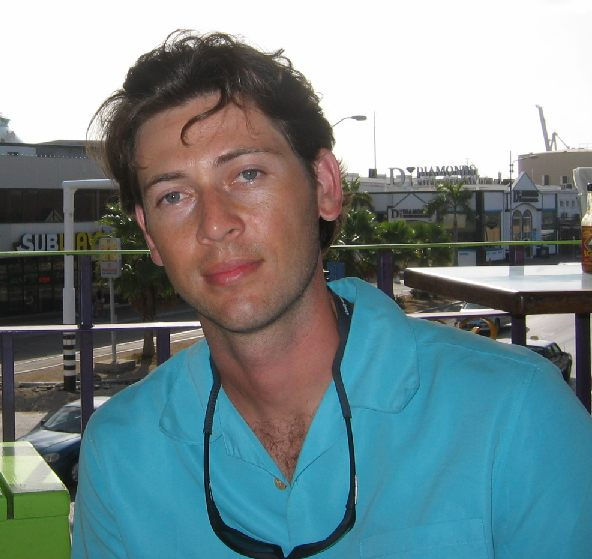

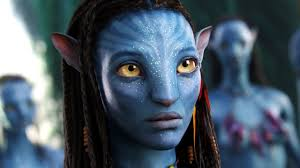

(1, 559, 592, 3)
(1, 3, 559, 592)
error = 0.8869824267939675
error2 = 0.9308463840113939
(1, 168, 300, 3)
(1, 3, 168, 300)
error = 0.5602801418979169
error2 = 0.7963814906260801


In [54]:
from PIL import Image

from ignite.metrics import SSIM

from numpy.random import rand
from numpy.random import seed
seed(1)

urls = ("aruba_eu_rec.jpg", "avatar.woman.jpg")
# Read image
imgs = list()

for u in urls:
    imgs.append(Image.open(u))
    imgs[-1].show()

ssim_obj = SSIM(data_range=1.2)

for i in imgs:
    a = np.array(i, dtype=float)
    a = np.array(i, dtype=float)
    new_shape = (1,) + a.shape
    print(new_shape)
    a = a/np.max(a)
    a = a.reshape(new_shape)
    a = np.transpose(a,(0,3,1,2))
    print(a.shape)
    b = a.copy()
    b = b-0.1
    #print (a)
    ssim_obj.reset()
    ssim_obj.update([torch.from_numpy(a),torch.from_numpy(b)])
    error = ssim_obj.compute()
    error2 = ssim(torch.from_numpy(a),torch.from_numpy(b))
    #a = np.zeros(a_.shape)
    
    print(f"error = {error}")
    print(f"error2 = {error2}")
    #print(a)
    #print(b)







